# EN3160 Assignment 03: Neural Networks
**Karunarathna G.K.T. | 230322U**  
Repository: https://github.com/KavijaK/EN3160_A03  
GitHub profile: https://github.com/KavijaK


In [1]:
from pathlib import Path
import json
import random
import time
import urllib.request
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

SEED = 230322
RETRAIN = False  # Set True to repeat completed training runs.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
data_dir, results, checkpoints = map(Path, ["data", "results", "checkpoints"])
for folder in [data_dir, results, checkpoints]:
    folder.mkdir(exist_ok=True)
torch.hub.set_dir(str(data_dir / "torch_hub"))
print(f"PyTorch {torch.__version__}; device: {device}; seed: {SEED}")


PyTorch 2.14.1; device: cpu; seed: 230322


In [2]:
def make_loaders(train, train_eval, evaluation, batch_size):
    generator = torch.Generator().manual_seed(SEED)
    return {
        "train": DataLoader(train, batch_size, shuffle=True, generator=generator),
        "train_eval": DataLoader(train_eval, batch_size, shuffle=False),
        "eval": DataLoader(evaluation, batch_size, shuffle=False),
    }

@torch.inference_mode()
def evaluate(predict, loader, classes):
    loss, correct, count = 0., 0, 0
    matrix = torch.zeros(classes, classes, dtype=torch.int64)
    for images, labels in loader:
        logits = predict(images.to(device))
        target = labels.to(device)
        prediction = logits.argmax(1)
        loss += F.cross_entropy(logits, target, reduction="sum").item()
        correct += (prediction == target).sum().item()
        count += len(labels)
        matrix += torch.bincount(labels*classes + prediction.cpu(),
                                 minlength=classes**2).reshape(classes, classes)
    return {"loss": loss/count, "accuracy": 100*correct/count}, matrix.numpy()

def fit(model, loaders, name, epochs, optimizer, classes, scheduler=None, frozen=False):
    weights, log = checkpoints / f"{name}.pt", results / f"{name}_history.json"
    if not RETRAIN and weights.exists() and log.exists():
        history = json.loads(log.read_text())
        if len(history) == epochs:
            model.load_state_dict(torch.load(weights, map_location=device, weights_only=True))
            print(f"{name}: loaded completed {epochs}-epoch run")
            for row in history:
                print(f"{row['epoch']:02d}: train loss {row['train_loss']:.4f}, "
                      f"accuracy {row['train_accuracy']:.2f}%; evaluation loss "
                      f"{row['eval_loss']:.4f}, accuracy {row['eval_accuracy']:.2f}%")
            return history
    history = []
    started = time.perf_counter()
    for epoch in range(1, epochs+1):
        model.train(not frozen)  # Frozen backbone keeps its pretrained BN statistics.
        for images, labels in loaders["train"]:
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(images.to(device)), labels.to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        train, _ = evaluate(model, loaders["train_eval"], classes)
        heldout, _ = evaluate(model, loaders["eval"], classes)
        row = dict(epoch=epoch, train_loss=train["loss"], train_accuracy=train["accuracy"],
                   eval_loss=heldout["loss"], eval_accuracy=heldout["accuracy"],
                   elapsed_seconds=time.perf_counter()-started)
        history.append(row)
        log.write_text(json.dumps(history, indent=2))
        print(f"{name} {epoch:02d}/{epochs}: train loss {train['loss']:.4f}, "
              f"accuracy {train['accuracy']:.2f}%; evaluation loss {heldout['loss']:.4f}, "
              f"accuracy {heldout['accuracy']:.2f}%", flush=True)
        if scheduler is not None:
            scheduler.step()
    torch.save(model.state_dict(), weights)
    return history

def plot_history(histories, filename, evaluation_label="Test"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, history in histories.items():
        epochs = [r["epoch"] for r in history]
        for ax, metric in zip(axes, ["accuracy", "loss"]):
            line, = ax.plot(epochs, [r[f"train_{metric}"] for r in history], label=f"{name}: train")
            ax.plot(epochs, [r[f"eval_{metric}"] for r in history], "--",
                    color=line.get_color(), label=f"{name}: {evaluation_label.lower()}")
            ax.set(xlabel="Epoch", ylabel="Accuracy (%)" if metric=="accuracy" else "Cross-entropy loss")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(results / filename, dpi=160, bbox_inches="tight")
    plt.show()

def plot_confusions(matrices, labels, filename):
    fig, axes = plt.subplots(1, len(matrices), figsize=(6*len(matrices), 5), squeeze=False)
    for ax, (name, matrix) in zip(axes.flat, matrices.items()):
        ax.imshow(matrix, cmap="Blues")
        ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
               xticklabels=labels, yticklabels=labels, xlabel="Predicted", ylabel="True", title=name)
        for (row, col), value in np.ndenumerate(matrix):
            ax.text(col, row, str(value), ha="center", va="center", fontsize=7,
                    color="white" if value > matrix.max()/2 else "black")
    fig.tight_layout()
    fig.savefig(results / filename, dpi=160, bbox_inches="tight")
    plt.show()


## Question 1: CIFAR-10, manual forward pass and backpropagation
Architecture: 3072 -> 100 sigmoid -> 10 logits. Cross-entropy; 10 epochs; batch size 50;
learning rate 0.1 with factor 0.9 per epoch. Gradients and parameter updates are manual.


In [3]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((.5, .5, .5), (.5, .5, .5))])
cifar_train = datasets.CIFAR10(data_dir, train=True, download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(data_dir, train=False, download=True, transform=cifar_transform)
cifar = make_loaders(cifar_train, cifar_train, cifar_test, batch_size=50)
print(f"CIFAR-10: {len(cifar_train)} training / {len(cifar_test)} test images")


CIFAR-10: 50000 training / 10000 test images


Loaded completed 10-epoch manual run


After 10 epochs: training accuracy 53.42%; test accuracy 47.87%


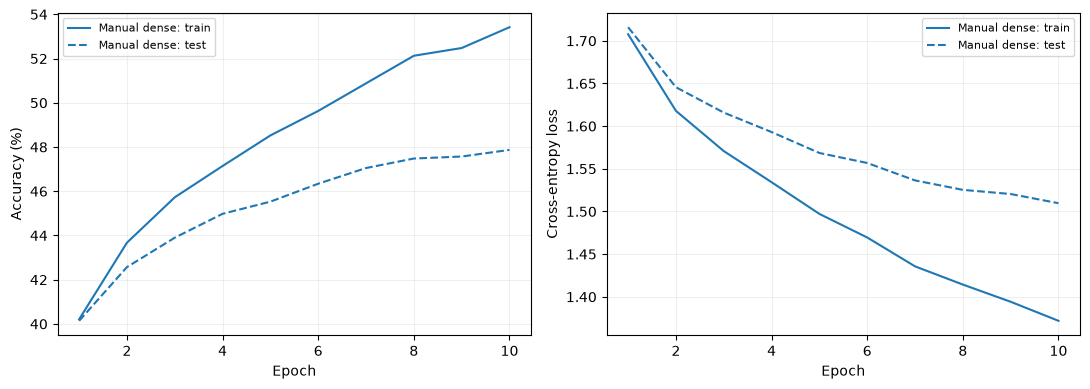

In [4]:
torch.manual_seed(SEED)
W1 = torch.randn(3072, 100, device=device) / np.sqrt(3072)
b1 = torch.zeros(100, device=device)
W2 = torch.randn(100, 10, device=device) / np.sqrt(100)
b2 = torch.zeros(10, device=device)
parameters = [W1, b1, W2, b2]

def dense_forward(images):
    return torch.sigmoid(images.flatten(1) @ W1 + b1) @ W2 + b2

def manual_gradients(x, labels, parameters):
    W1, b1, W2, b2 = parameters
    hidden = torch.sigmoid(x @ W1 + b1)
    logits = hidden @ W2 + b2
    log_prob = logits - logits.logsumexp(dim=1, keepdim=True)
    rows = torch.arange(len(labels), device=x.device)
    loss = -log_prob[rows, labels].mean()
    dz = log_prob.exp()
    dz[rows, labels] -= 1
    dz /= len(labels)
    dh = (dz @ W2.T) * hidden * (1-hidden)
    return loss, [x.T @ dh, dh.sum(0), hidden.T @ dz, dz.sum(0)]

q1_weights, q1_log = checkpoints / "dense_manual.pt", results / "dense_manual_history.json"
if not RETRAIN and q1_weights.exists() and q1_log.exists():
    loaded = torch.load(q1_weights, map_location=device, weights_only=True)
    for parameter, saved in zip(parameters, loaded):
        parameter.copy_(saved)
    dense_history = json.loads(q1_log.read_text())
    print("Loaded completed 10-epoch manual run")
else:
    dense_history, learning_rate = [], .1
    for epoch in range(1, 11):
        for images, labels in cifar["train"]:
            x, target = images.to(device).flatten(1), labels.to(device)
            _, gradients = manual_gradients(x, target, parameters)
            for parameter, gradient in zip(parameters, gradients):
                parameter -= learning_rate * gradient
        train, _ = evaluate(dense_forward, cifar["train_eval"], 10)
        test, _ = evaluate(dense_forward, cifar["eval"], 10)
        dense_history.append(dict(epoch=epoch, train_loss=train["loss"],
            train_accuracy=train["accuracy"], eval_loss=test["loss"], eval_accuracy=test["accuracy"]))
        q1_log.write_text(json.dumps(dense_history, indent=2))
        print(f"Epoch {epoch:02d}/10: train {train['accuracy']:.2f}%, test {test['accuracy']:.2f}%", flush=True)
        learning_rate *= .9
    torch.save(parameters, q1_weights)
train, _ = evaluate(dense_forward, cifar["train_eval"], 10)
test, _ = evaluate(dense_forward, cifar["eval"], 10)
print(f"After 10 epochs: training accuracy {train['accuracy']:.2f}%; test accuracy {test['accuracy']:.2f}%")
plot_history({"Manual dense": dense_history}, "q1_history.png")


## Question 2: MNIST CNN comparison
Both models: full MNIST split; 10 epochs; batch size 128; Adam, learning rate 0.001;
identical normalization and seeded shuffle. Epoch metrics use evaluation mode on the full
training/test sets.


In [5]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((.1307,), (.3081,))])
mnist_train = datasets.MNIST(data_dir, train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(data_dir, train=False, download=True, transform=mnist_transform)
print(f"MNIST: {len(mnist_train)} training / {len(mnist_test)} test images")

class LeNet5(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2), nn.Flatten(),
            nn.Linear(400, 120), nn.Tanh(), nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))

class SmallCNN(nn.Sequential):
    def __init__(self):
        layers = []
        for incoming, outgoing in [(1, 16), (16, 32), (32, 64)]:
            layers += [nn.Conv2d(incoming, outgoing, 3, padding=1),
                       nn.BatchNorm2d(outgoing), nn.ReLU(), nn.MaxPool2d(2)]
        super().__init__(*layers, nn.Flatten(), nn.Dropout(.3), nn.Linear(64*3*3, 10))


MNIST: 60000 training / 10000 test images


LeNet5: loaded completed 10-epoch run
01: train loss 0.1104, accuracy 96.74%; evaluation loss 0.1090, accuracy 96.63%
02: train loss 0.0621, accuracy 98.13%; evaluation loss 0.0695, accuracy 97.77%
03: train loss 0.0452, accuracy 98.61%; evaluation loss 0.0572, accuracy 98.23%
04: train loss 0.0348, accuracy 98.97%; evaluation loss 0.0509, accuracy 98.28%
05: train loss 0.0283, accuracy 99.16%; evaluation loss 0.0440, accuracy 98.56%
06: train loss 0.0212, accuracy 99.38%; evaluation loss 0.0382, accuracy 98.82%
07: train loss 0.0197, accuracy 99.40%; evaluation loss 0.0373, accuracy 98.79%
08: train loss 0.0174, accuracy 99.46%; evaluation loss 0.0410, accuracy 98.71%
09: train loss 0.0148, accuracy 99.53%; evaluation loss 0.0388, accuracy 98.72%
10: train loss 0.0205, accuracy 99.34%; evaluation loss 0.0433, accuracy 98.60%


LeNet5: training 99.34%; test 98.60%
SmallCNN: loaded completed 10-epoch run
01: train loss 0.0495, accuracy 98.54%; evaluation loss 0.0477, accuracy 98.46%
02: train loss 0.0301, accuracy 99.13%; evaluation loss 0.0325, accuracy 98.83%
03: train loss 0.0234, accuracy 99.30%; evaluation loss 0.0292, accuracy 99.02%
04: train loss 0.0203, accuracy 99.40%; evaluation loss 0.0268, accuracy 99.19%
05: train loss 0.0220, accuracy 99.31%; evaluation loss 0.0313, accuracy 98.98%
06: train loss 0.0176, accuracy 99.51%; evaluation loss 0.0296, accuracy 99.10%
07: train loss 0.0123, accuracy 99.63%; evaluation loss 0.0211, accuracy 99.30%
08: train loss 0.0121, accuracy 99.64%; evaluation loss 0.0249, accuracy 99.12%
09: train loss 0.0102, accuracy 99.67%; evaluation loss 0.0249, accuracy 99.15%
10: train loss 0.0077, accuracy 99.78%; evaluation loss 0.0221, accuracy 99.33%


SmallCNN: training 99.78%; test 99.33%


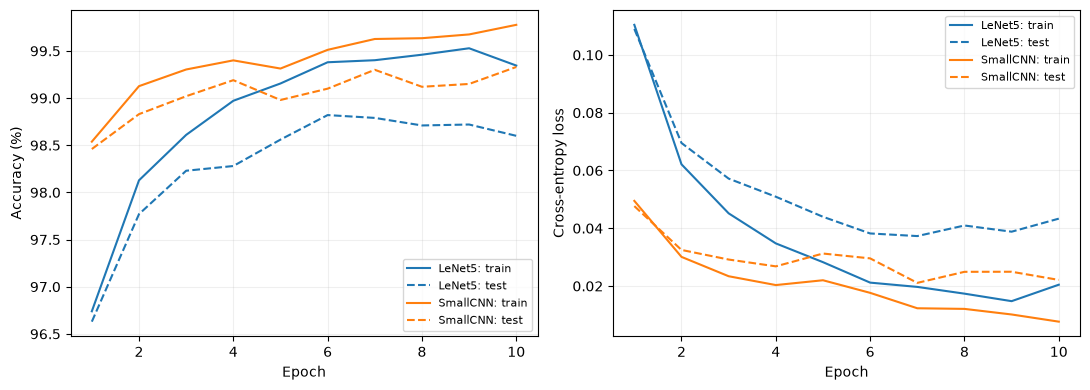

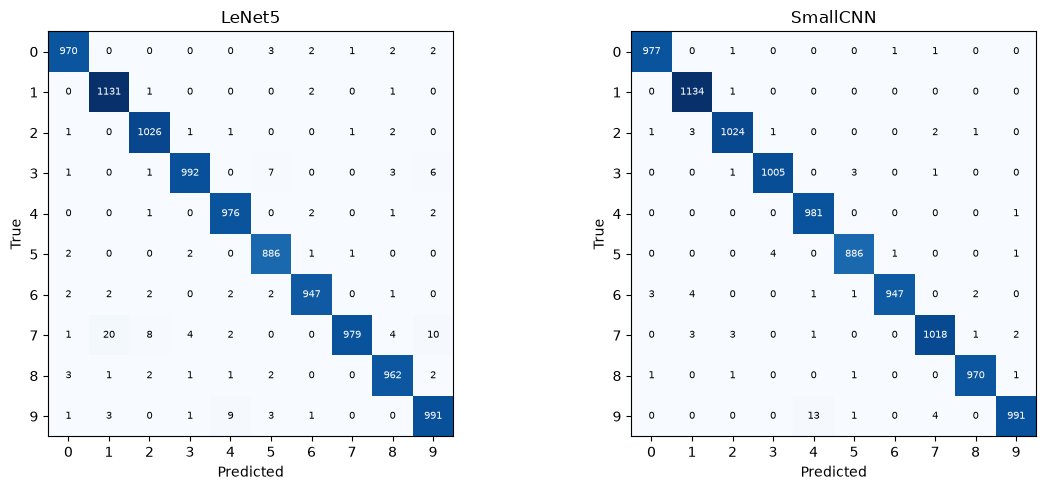

In [6]:
mnist_histories, mnist_matrices, mnist_summary = {}, {}, []
for name, architecture in [("LeNet5", LeNet5), ("SmallCNN", SmallCNN)]:
    torch.manual_seed(SEED)
    model = architecture().to(device)
    loaders = make_loaders(mnist_train, mnist_train, mnist_test, 128)
    optimizer = torch.optim.Adam(model.parameters(), lr=.001)
    history = fit(model, loaders, name, 10, optimizer, classes=10)
    model.eval()
    train, _ = evaluate(model, loaders["train_eval"], 10)
    test, matrix = evaluate(model, loaders["eval"], 10)
    mnist_histories[name], mnist_matrices[name] = history, matrix
    mnist_summary.append(dict(model=name, train_accuracy=train["accuracy"],
        test_accuracy=test["accuracy"], train_loss=train["loss"], test_loss=test["loss"],
        parameters=sum(p.numel() for p in model.parameters())))
    np.save(results / f"{name}_confusion.npy", matrix)
    print(f"{name}: training {train['accuracy']:.2f}%; test {test['accuracy']:.2f}%")
(results / "q2_summary.json").write_text(json.dumps(mnist_summary, indent=2));
plot_history(mnist_histories, "q2_history.png")
plot_confusions(mnist_matrices, list(range(10)), "q2_confusion.png")


## Question 3: ResNet18 transfer learning
ImageNet1K-pretrained ResNet18; hymenoptera train/validation split; 25 epochs per method;
batch size 16; SGD (learning rate 0.001, momentum 0.9); StepLR (7 epochs, factor 0.1).


In [7]:
archive = data_dir / "hymenoptera_data.zip"
if not (data_dir / "hymenoptera_data").exists():
    urllib.request.urlretrieve("https://download.pytorch.org/tutorial/hymenoptera_data.zip", archive)
    with zipfile.ZipFile(archive) as zipped:
        zipped.extractall(data_dir)
weights = models.ResNet18_Weights.IMAGENET1K_V1
evaluation_transform = weights.transforms()
training_transform = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize([.485, .456, .406], [.229, .224, .225])])
hym_root = data_dir / "hymenoptera_data"
hym_train = datasets.ImageFolder(hym_root / "train", training_transform)
hym_train_eval = datasets.ImageFolder(hym_root / "train", evaluation_transform)
hym_val = datasets.ImageFolder(hym_root / "val", evaluation_transform)
print(f"Hymenoptera: {len(hym_train)} train / {len(hym_val)} validation; {hym_train.classes}")


Hymenoptera: 244 train / 153 validation; ['ants', 'bees']


Fine_tuning: loaded completed 25-epoch run
01: train loss 0.2612, accuracy 92.62%; evaluation loss 0.2813, accuracy 92.81%
02: train loss 0.1697, accuracy 93.85%; evaluation loss 0.2539, accuracy 90.20%
03: train loss 0.1236, accuracy 95.49%; evaluation loss 0.1926, accuracy 92.16%
04: train loss 0.0588, accuracy 99.59%; evaluation loss 0.1582, accuracy 94.77%
05: train loss 0.0481, accuracy 99.18%; evaluation loss 0.1654, accuracy 94.77%
06: train loss 0.0344, accuracy 100.00%; evaluation loss 0.1527, accuracy 94.77%
07: train loss 0.0320, accuracy 100.00%; evaluation loss 0.1572, accuracy 94.12%
08: train loss 0.0312, accuracy 99.59%; evaluation loss 0.1621, accuracy 95.42%
09: train loss 0.0307, accuracy 100.00%; evaluation loss 0.1558, accuracy 94.12%
10: train loss 0.0356, accuracy 100.00%; evaluation loss 0.1599, accuracy 95.42%
11: train loss 0.0307, accuracy 100.00%; evaluation loss 0.1568, accuracy 95.42%
12: train loss 0.0268, accuracy 100.00%; evaluation loss 0.1536, accurac

Fine_tuning: training 100.00%; validation 94.12%


Feature_extraction: loaded completed 25-epoch run
01: train loss 0.2281, accuracy 94.26%; evaluation loss 0.2302, accuracy 94.77%
02: train loss 0.1656, accuracy 93.44%; evaluation loss 0.1989, accuracy 94.12%
03: train loss 0.1095, accuracy 96.72%; evaluation loss 0.1385, accuracy 95.42%
04: train loss 0.0948, accuracy 96.72%; evaluation loss 0.1315, accuracy 95.42%
05: train loss 0.0840, accuracy 97.13%; evaluation loss 0.1307, accuracy 95.42%
06: train loss 0.0799, accuracy 97.13%; evaluation loss 0.1304, accuracy 95.42%
07: train loss 0.0729, accuracy 97.54%; evaluation loss 0.1380, accuracy 95.42%
08: train loss 0.0723, accuracy 97.54%; evaluation loss 0.1370, accuracy 95.42%
09: train loss 0.0717, accuracy 97.54%; evaluation loss 0.1332, accuracy 95.42%
10: train loss 0.0731, accuracy 97.54%; evaluation loss 0.1312, accuracy 95.42%
11: train loss 0.0722, accuracy 97.95%; evaluation loss 0.1315, accuracy 95.42%
12: train loss 0.0721, accuracy 97.95%; evaluation loss 0.1311, accura

Feature_extraction: training 97.95%; validation 95.42%


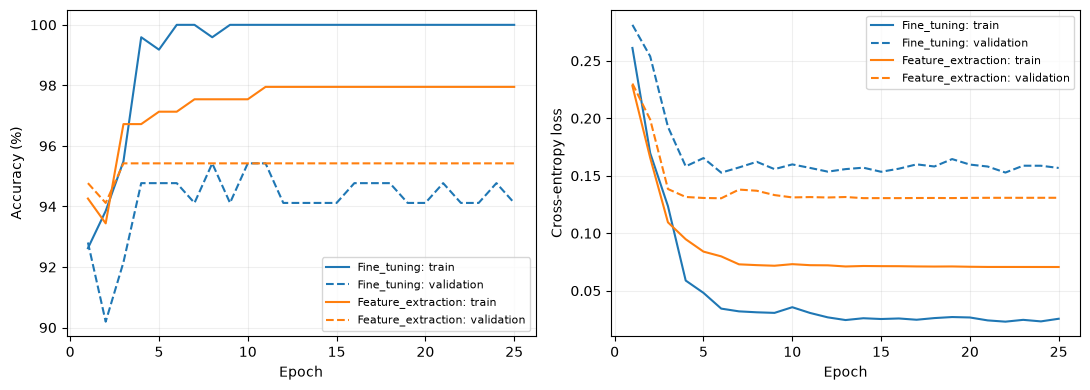

In [8]:
transfer_histories, transfer_summary = {}, []
for name, frozen in [("Fine_tuning", False), ("Feature_extraction", True)]:
    torch.manual_seed(SEED)
    model = models.resnet18(weights=weights)
    if frozen:
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)
    model = model.to(device)
    loaders = make_loaders(hym_train, hym_train_eval, hym_val, 16)
    optimizer = torch.optim.SGD((p for p in model.parameters() if p.requires_grad),
                                lr=.001, momentum=.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=.1)
    history = fit(model, loaders, name, 25, optimizer, classes=2,
                  scheduler=scheduler, frozen=frozen)
    model.eval()
    train, _ = evaluate(model, loaders["train_eval"], 2)
    val, _ = evaluate(model, loaders["eval"], 2)
    transfer_histories[name] = history
    transfer_summary.append(dict(method=name, train_accuracy=train["accuracy"],
        validation_accuracy=val["accuracy"], train_loss=train["loss"], validation_loss=val["loss"],
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)))
    print(f"{name}: training {train['accuracy']:.2f}%; validation {val['accuracy']:.2f}%")
(results / "q3_summary.json").write_text(json.dumps(transfer_summary, indent=2));
plot_history(transfer_histories, "q3_history.png", evaluation_label="Validation")


Source: [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
